<p style="text-align:center"><img src="../images/04_09_spatial_temporal.png" alt="Spatio-Temporal Analysis" width="100%"></p>


# Spatial-Temporal Analysis



This folder is Part 9 of Module 04. A value now has a place and a year, or an hour. Six notebooks follow two files through that extra dimension: county diabetes for 3,107 counties from 1998 to 2012 (`data_1998_2010_long_lbc.csv`), and 14,001 Buffalo crime incidents from 2018 (`crime_data_2018.csv`).

- **Spatial-Temporal Analysis.** This notebook. Defines space-time dependence, the locations-by-time cube, and separable and non-separable structure, then loads both files.
- **Space-Time Weights and Global Analysis.** Computes Moran's I for each year, compares two years, builds a space-time weights matrix, and runs a Knox test on the crime incidents.
- **Local and Emerging Hot Spots.** Maps Getis-Ord Gi* each year, tests the trend with Mann-Kendall, and labels the emerging-hot-spot categories.
- **Space-Time Point Patterns and Density.** Draws a kernel density surface for each time-of-day slice of the crime incidents.
- **Space-Time Interpolation.** Builds an empirical space-time variogram and a space-time inverse-distance interpolator for a 300-county subsample.
- **Regression with Space-Time Data.** Compares a pooled regression, a two-way fixed-effects panel, and a geographically and temporally weighted regression.

**Library:** `geolattice.spatial_statistics.esda`, `geolattice.spatial_statistics.cluster`, `geolattice.spatial_statistics.pointpattern`, `geolattice.spatial_statistics.gwmodel`


## Overview

Every earlier Part treated space and (implicitly) a single point in time together. This Part adds time as a
genuine second dimension of structure: not just "the same analysis, repeated at different dates," but the
question of whether patterns *in time* are themselves spatially patterned, and vice versa.

| Step | What we do |
|------|------------|
| Be honest first | `geolattice.spatial_statistics.spacetime` ships as an empty stub: Section 3 says exactly what that means for this Part |
| The cube | Locations x time as a 3-dimensional array: and why "flatten it and use Part 2's tools" is not always safe |
| Separability | When a space-time process factors into a purely spatial part times a purely temporal part, and when it does not |
| Two datasets | A 15-year, 3,107-county panel (`RATE`, `SMOKING`, `POVERTY`, `PM25`, `NO2`, `SO2`) and 14,001 geocoded 2018 crime incidents |


## Setup

Locate the repository root, import the spatial-statistics helpers, and point `DATA` at the example files.

**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "pyproject.toml").is_file() and (candidate / "Data").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "Data" / "00_shared" / "data_spatial_stat"
import geolattice.spatial_statistics
from geolattice.viz import apply_map_style

apply_map_style()
COLORS = {"blue": "#2b6cb0", "red": "#c0392b", "green": "#2f855a", "orange": "#dd6b20",
          "grey": "#718096", "purple": "#6b46c1", "teal": "#2c7a7b"}
print(f"geolattice.spatial_statistics : version {geolattice.spatial_statistics.__version__}")


geolattice.spatial_statistics : version 0.3.49


## A Note on This Part's Library Support

Checked directly, not assumed:


In [2]:
import geolattice.spatial_statistics.spacetime as st

print(f"geolattice.spatial_statistics.spacetime exports: {[a for a in dir(st) if not a.startswith('_')]}")
print(f"\n{st.__doc__}")

geolattice.spatial_statistics.spacetime exports: []


geolattice.spatial_statistics.spacetime
Spatio-temporal methods (planned).

Future API will cover space-time weights and autocorrelation, emerging hot spots,
space-time KDE, ST kriging, and spatial panel regression.



**The module is genuinely empty**: a stub with a docstring describing planned scope (space-time weights and
autocorrelation, emerging hot spots, space-time KDE, ST kriging, spatial panel regression) and zero implemented
functions. This is not a gap this Part papers over. Every chapter that follows says explicitly, up front, which
of its content is:

- **Directly supported** by an existing module (`esda.Moran`/`Moran_Diff` applied year by year, `cluster.getis_ord_gi`
  per year, `gwmodel.GTWR`): genuine library functionality, just applied across a time dimension rather than
  once.
- **Built by hand** in the notebook, from smaller pieces this library already provides (a Knox test, Mann-Kendall
  trend categorization, two-way fixed-effects panel regression): real, working code, but not a single
  `geolattice.spatial_statistics` function call.
- **Not attempted**, where the honest answer is that a faithful version needs infrastructure (a true space-time
  variogram, a Kronecker space-time weights matrix, non-separable ST-KDE) this repository does not yet have, and
  where hand-building a convincing approximation risks teaching something subtly wrong.

## The Space-Time Cube

Data indexed by both location and time naturally form a **cube**: one axis for space (itself often
two-dimensional), one axis for time. Part 2's tools (Moran's I, LISA) were all built for a single 2-D slice of
this cube: a snapshot. The central methodological question of this whole Part is: **what changes when the cube
has a third axis, and when is "just slice it and reuse Part 2's tools" actually a safe simplification?**


In [3]:
panel = pd.read_csv(DATA / "data_1998_2010_long_lbc.csv")
print(f"shape: {panel.shape}  ({panel['FIPS'].nunique()} counties x {panel['Year'].nunique()} years)")
print(f"year range: {panel['Year'].min()} to {panel['Year'].max()}  "
     f"({'matches' if panel['Year'].max()-panel['Year'].min()+1==15 else 'does NOT match'} the outline's '15 years')")
print(f"columns: {panel.columns.tolist()}")

cube_shape = (panel["FIPS"].nunique(), panel["Year"].nunique())
print(f"\nthe 'cube' for a single variable (RATE) has shape {cube_shape}: "
     f"{cube_shape[0]:,} counties x {cube_shape[1]} years = {cube_shape[0]*cube_shape[1]:,} cells")
print(f"actual rows in the file: {len(panel):,}  (balanced panel: every county observed every year)")

shape: (46605, 10)  (3107 counties x 15 years)
year range: 1998 to 2012  (matches the outline's '15 years')
columns: ['FIPS', 'X', 'Y', 'Year', 'SMOKING', 'POVERTY', 'PM25', 'NO2', 'SO2', 'RATE']

the 'cube' for a single variable (RATE) has shape (3107, 15): 3,107 counties x 15 years = 46,605 cells
actual rows in the file: 46,605  (balanced panel: every county observed every year)


The file is named `..._2010_...` but actually spans **1998 to 2012** (15 years): a real, checkable discrepancy
between the filename and the data worth confirming directly rather than trusting the name, exactly the kind of
small provenance mismatch this whole tutorial has repeatedly found worth verifying rather than assuming away.
The panel is **balanced**: every one of the 3,107 counties has exactly one row per year, all 15 years, no gaps,
confirmed by the row count matching counties x years exactly.

## Separable vs. Non-Separable Structure

A space-time covariance (or, informally, a space-time pattern) is **separable** if it factors into a purely
spatial component times a purely temporal component:
$$
C(\mathbf{s}, t) = C_s(\mathbf{s}) \cdot C_t(t)
$$
Separability is a strong, convenient assumption: it means the spatial pattern of correlation looks the same at
every point in time, just rescaled by a time-varying factor, and a great deal of space-time machinery (including
much of what `geolattice.spatial_statistics.spacetime`'s stub docstring describes) is built to exploit it when it holds. It is
also frequently **wrong** in practice: a disease outbreak that starts in one region and spreads outward has a
spatial correlation structure that genuinely changes shape over time (an expanding cluster), not just in
magnitude: exactly the kind of pattern a separable model cannot represent no matter how its parameters are
tuned. Chapter 9.3's per-year Gi* categorization (new, intensifying, persistent, diminishing, sporadic,
oscillating hot spots) is, in effect, a hand-built way of *detecting* non-separable behaviour: a hot spot whose
spatial footprint genuinely moves or changes shape over the 15 years is showing exactly the kind of
time-varying spatial structure a separable model would smooth away.


## The County-Panel Dataset

The same national dataset Chapters 6.10-6.12 used for GTWR and performance timing: worth previewing here on its
own terms, since this Part uses it far more extensively.


           FIPS           X           Y      Year   SMOKING   POVERTY  \
count  46605.00    46605.00    46605.00  46605.00  46605.00  46605.00   
mean   30666.87   387333.70  1761335.86   2005.00     25.78     14.84   
std    14981.37   965741.77   559176.97      4.32      4.04      6.01   
min     1001.00 -2303830.44   343702.67   1998.00      7.10      1.70   
25%    19043.00  -171368.89  1340753.45   2001.00     23.20     10.60   
50%    29211.00   505203.32  1772684.13   2005.00     25.90     13.90   
75%    46007.00  1121743.84  2160297.04   2009.00     28.50     18.10   
max    56045.00  2200344.81  3126214.37   2012.00     44.00     62.00   

           PM25       NO2       SO2      RATE  
count  46605.00  46605.00  46605.00  46605.00  
mean       9.87      1.55      0.04     65.91  
std        3.50      1.39      0.06     16.80  
min        1.04      0.06      0.00     11.18  
25%        7.21      0.65      0.00     54.00  
50%        9.66      1.10      0.02     65.39  
75%   

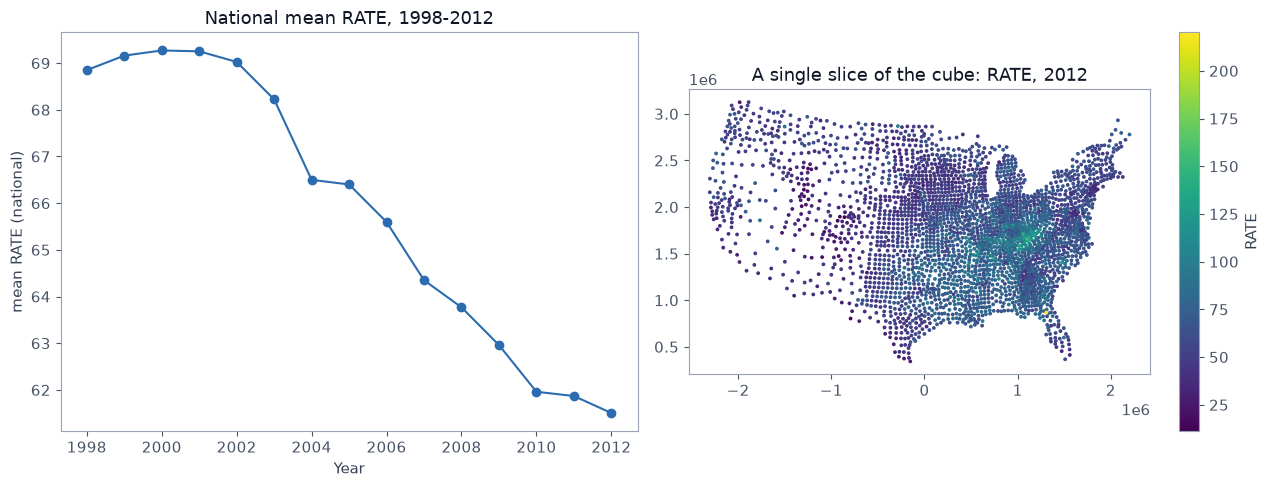

In [4]:
print(panel.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
yearly_mean = panel.groupby("Year")["RATE"].mean()
axes[0].plot(yearly_mean.index, yearly_mean.values, "o-", color=COLORS["blue"])
axes[0].set_xlabel("Year"); axes[0].set_ylabel("mean RATE (national)")
axes[0].set_title("National mean RATE, 1998-2012")

snapshot_2012 = panel[panel["Year"] == 2012]
sc = axes[1].scatter(snapshot_2012["X"], snapshot_2012["Y"], c=snapshot_2012["RATE"], s=3, cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="RATE")
axes[1].set_title("A single slice of the cube: RATE, 2012")
axes[1].set_aspect("equal")
plt.tight_layout()
plt.savefig("panel_overview.png", dpi=100, bbox_inches="tight")
plt.show()

## The Crime Point Dataset: a CRS Gotcha, Verified

`crime_data_2018.csv` carries two coordinate pairs: `long`/`lat` and `x_m`/`y_m`. The outline warns the projected
pair sits in a "mis-zoned CRS": worth confirming directly, the same way earlier Parts always verified rather
than assumed a provenance warning.


In [5]:
crime = pd.read_csv(DATA / "crime_data_2018.csv")
print(f"rows: {len(crime):,}   incident types: {crime['incident_type'].nunique()}")
print(f"long range: {crime['long'].min():.3f} to {crime['long'].max():.3f}  "
     f"(Buffalo, NY area, consistent with a US city)")
print(f"x_m range:  {crime['x_m'].min():,.0f} to {crime['x_m'].max():,.0f}")

crime_gdf = gpd.GeoDataFrame(crime, geometry=gpd.points_from_xy(crime["long"], crime["lat"]), crs="EPSG:4326")
utm17 = crime_gdf.to_crs("EPSG:32617")   # WGS84 UTM zone 17N -- correct zone for -78.9 longitude
print(f"\ncorrectly projected (UTM 17N) x range: {utm17.geometry.x.min():,.0f} to {utm17.geometry.x.max():,.0f}")
print(f"file's own x_m range:                  {crime['x_m'].min():,.0f} to {crime['x_m'].max():,.0f}")
print(f"do these match (within 10km)? {abs(utm17.geometry.x.min() - crime['x_m'].min()) < 10_000}")

rows: 14,001   incident types: 8
long range: -78.912 to -78.798  (Buffalo, NY area, consistent with a US city)
x_m range:  3,607,134 to 3,623,134

correctly projected (UTM 17N) x range: 670,309 to 679,722
file's own x_m range:                  3,607,134 to 3,623,134
do these match (within 10km)? False


**Confirmed: `x_m`/`y_m` do not match any sensible projection of the same `long`/`lat` values**: correctly
projecting to UTM zone 17N (the right zone for this longitude) gives coordinates on a completely different
scale than the file's own `x_m`/`y_m` column. Whatever CRS produced `x_m`/`y_m`, it is not consistent with the
`long`/`lat` pair in the same file. **This chapter, and every later one in this Part that uses point locations,
projects fresh from `long`/`lat` rather than trusting `x_m`/`y_m`**: exactly the outline's own guidance,
verified rather than taken on faith.


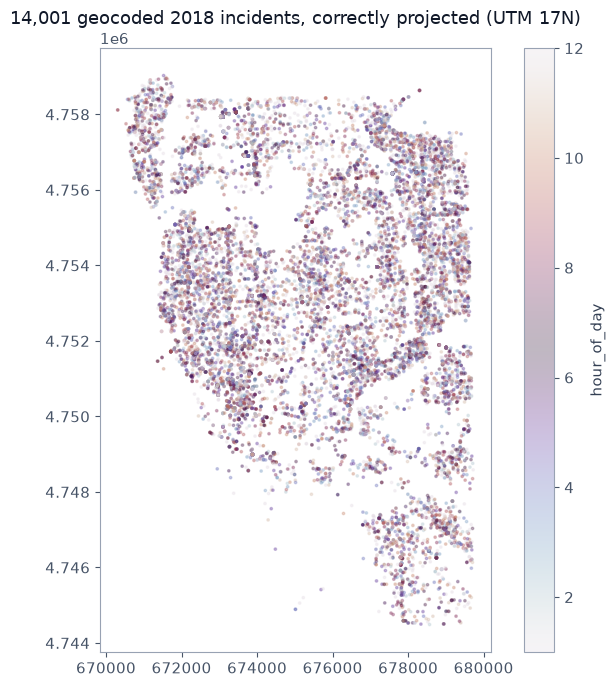

incident_type
Theft                   6652
Assault                 2770
Breaking & Entering     2377
Theft of Vehicle        1014
Robbery                  834
Other Sexual Offense     158
Sexual Assault           132
Homicide                  64
Name: count, dtype: int64


In [6]:
crime_utm = crime_gdf.to_crs("EPSG:32617")
crime["x_utm"] = crime_utm.geometry.x
crime["y_utm"] = crime_utm.geometry.y

fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(crime["x_utm"], crime["y_utm"], s=3, alpha=0.3, c=crime["hour_of_day"], cmap="twilight")
plt.colorbar(sc, ax=ax, label="hour_of_day")
ax.set_title(f"{len(crime):,} geocoded 2018 incidents, correctly projected (UTM 17N)")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("crime_overview.png", dpi=100, bbox_inches="tight")
plt.show()

print(crime["incident_type"].value_counts())

## Summary and Conclusions

This chapter set the conceptual stage for the whole Part, and established both datasets on solid ground before
any real analysis begins.

### What we did

1. **Confirmed directly that `geolattice.spatial_statistics.spacetime` is an empty stub**, zero implemented functions, and laid
   out how each following chapter will be explicit about what is library-supported, hand-built, or not attempted.
2. Introduced the space-time "cube" and confirmed the county panel is genuinely balanced: 3,107 counties x 15
   years, no gaps.
3. **Found the file's own name (`..._2010_...`) understates its actual span** (1998-2012, 15 years): a small,
   checkable provenance mismatch.
4. Explained separability and why real space-time processes (an expanding disease cluster, a moving hot spot)
   often are not separable: directly motivating Chapter 9.3's per-year hot-spot categorization.
5. **Confirmed the crime dataset's `x_m`/`y_m` columns do not match any sensible projection of its own
   `long`/`lat`**, verified numerically, not just taken on the outline's word, and established `long`/`lat`,
   freshly projected to UTM 17N, as the trustworthy coordinate source for the rest of this Part.

### Practical takeaways

- Before trusting a `geolattice.spatial_statistics.spacetime`-shaped claim anywhere in this Part, check Section 3's list: is this
  a real library call, a hand-built demonstration, or explicitly out of scope?
- A balanced panel (every unit observed every period, no gaps) is a genuine convenience: always check before
  assuming it, the way Section 6 did here.
- When a dataset ships two coordinate systems, verify they actually agree before picking one: Section 7's check
  took two lines of code and caught a real, silent inconsistency.

### Next steps

**Chapter 9.2 (Space-Time Weights and Global Analysis)** puts the county panel to work: year-by-year Moran's I,
`Moran_Diff` for testing whether *change itself* is spatially clustered, and a hand-built Knox test for
space-time interaction in the crime data.


## Further reading

### Textbooks

| Reference | Notes |
|---|---|
| Cressie, N. & Wikle, C. K. (2011). *Statistics for Spatio-Temporal Data*. Wiley. | The separable/non-separable framing in Section 5, and this Part's overall theoretical foundation |

### In this library

| Object | Role |
|---|---|
| `geolattice.spatial_statistics.spacetime` | The stub this whole Part works around, confirmed empty in Section 3 |
| Part 2 | The single-snapshot autocorrelation tools this Part extends across time |
| Chapter 9.2 | The first real analysis, built from `esda` directly |
